## Loading libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from statsmodels.tsa.stattools import adfuller, coint

## Loading dataset

In [34]:
data = pd.read_csv('../data/raw/merged_df_new.csv', parse_dates=['Date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2801 entries, 0 to 2800
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          2801 non-null   datetime64[ns]
 1   target        2801 non-null   float64       
 2   Oil_price     2801 non-null   float64       
 3   Gas_price     2801 non-null   float64       
 4   Nasdaq_price  2801 non-null   float64       
 5   Coal_price    2801 non-null   float64       
 6   stoxx_value   2801 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 153.3 KB


## Configuration
Wszystkie parametry w jednym miejscu.

In [27]:
periods = {
    "2015_2019": ("2015-01-01", "2019-12-31"),
    "2020_2022": ("2020-01-01", "2022-12-31"),
    "2023_2025": ("2023-01-01", "2025-11-21"),
}

TARGET = "target"
cols = data.columns.drop("Date").to_list()   # wszystkie kolumny poza datą (razem z target)
print(cols)

['target', 'Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price', 'stoxx_value']


## Functions

In [28]:
def split_periods(data, periods, date_col="Date"):
    """Dzieli dataset na podokresy (granice włącznie)."""
    return {
        name: data.loc[data[date_col].between(start, end)].copy()
        for name, (start, end) in periods.items()
    }


def check_periods(data_periods, date_col="Date"):
    """Sanity check: liczba obserwacji i zakres dat w każdym podokresie."""
    for name, df in data_periods.items():
        print(
            f"{name}: {len(df)} observations | "
            f"{df[date_col].min().date()} - {df[date_col].max().date()}"
        )


def apply_transform(df, cols, transform):
    """Zwraca kopię df z kolumnami `cols` w wersji 'raw' lub 'log'."""
    out = df.copy()
    if transform == "log":
        bad = [c for c in cols if (out[c] <= 0).any()]
        if bad:
            raise ValueError(f"Logarytm niemożliwy (wartości <= 0) w kolumnach: {bad}")
        out[cols] = np.log(out[cols])
    elif transform != "raw":
        raise ValueError("transform musi być 'raw' albo 'log'")
    return out


def plot_series(data_periods, cols, kind="line", transform="raw",
                target="target", figsize=None):
    """
    Jedna funkcja zamiast czterech pętli z wykresami.
    kind='line'    -> wykres każdej kolumny w czasie
    kind='scatter' -> target vs każda pozostała kolumna
    transform      -> 'raw' lub 'log'
    """
    if figsize is None:
        figsize = (8, 4) if kind == "line" and transform == "raw" else \
                  (12, 6) if kind == "line" else (5, 5)

    for period, df_raw in data_periods.items():
        df = apply_transform(df_raw, cols, transform)
        for col in cols:
            plt.figure(figsize=figsize)
            if kind == "line":
                plt.plot(df["Date"], df[col])
                plt.xlabel("Date")
                plt.ylabel(col)
                plt.title(f"{col} - period {period} ({transform})")
            elif kind == "scatter":
                if col == target:
                    plt.close()
                    continue
                plt.scatter(df[target], df[col])
                plt.xlabel("CO2 price")
                plt.ylabel(col)
                plt.title(f"CO2 price vs {col}, period {period} ({transform})")
            else:
                raise ValueError("kind musi być 'line' albo 'scatter'")
            plt.show()


def run_analysis(
    data_periods,
    cols,
    target="target",
    transforms=("raw", "log"),
    alpha_adf=0.01,
    alpha_coint=0.05,
    trends=("c", "ct", "ctt"),
    n_regressors=(1, 2),
    adf_diff=True,
    verbose=False,
):
    """
    Główna funkcja: ADF + kointegracja Engle'a-Grangera dla wszystkich
    kombinacji okres x transformacja x zestaw zmiennych x trend.

    Parametry
    ---------
    data_periods : dict {nazwa_okresu: DataFrame}
    cols         : lista kolumn (łącznie z target)
    transforms   : które wersje szeregów testować ('raw', 'log')
    trends       : trendy dla coint(): 'c', 'ct', 'ctt', 'n'
    n_regressors : (1, 2) = target vs pojedyncze zmienne ORAZ vs pary zmiennych
    adf_diff     : czy testować też pierwsze różnice

    Zwraca
    ------
    dict z dwoma DataFrame'ami: {'adf': ..., 'coint': ...}
    """
    regressors = [c for c in cols if c != target]
    adf_rows, coint_rows = [], []

    for period, df_raw in data_periods.items():
        for tf in transforms:
            df = apply_transform(df_raw, cols, tf)   # log liczony raz na (okres, transformację)

            # ---------- ADF ----------
            for col in cols:
                variants = [("level", df[col])]
                if adf_diff:
                    variants.append(("diff", df[col].diff().dropna()))
                for kind, s in variants:
                    res_adf = adfuller(s, result_object=True)
                    stat, p = res_adf.statistic, res_adf.pvalue
                    adf_rows.append({
                        "period": period, "transform": tf, "series": kind,
                        "variable": col, "adf_stat": stat, "p_value": p,
                        "stationary": p < alpha_adf,
                    })

            # ---------- Kointegracja ----------
            y = df[target]
            for k in n_regressors:
                for combo in combinations(regressors, k):
                    X = df[list(combo)]
                    for trend in trends:
                        p = coint(y, X, trend=trend)[1]
                        coint_rows.append({
                            "period": period, "transform": tf, "trend": trend,
                            "n_regressors": k, "regressors": " & ".join(combo),
                            "p_value": p, "cointegrated": p < alpha_coint,
                        })
                        if verbose:
                            print(f"{period} | {tf} | {trend} | {combo}: p={p:.4f}")

    return {
        "adf": pd.DataFrame(adf_rows),
        "coint": pd.DataFrame(coint_rows),
    }


### Dividing dataset into sub-periods + sanity check

In [29]:
data_periods = split_periods(data, periods)
check_periods(data_periods)

2015_2019: 1284 observations | 2015-01-02 - 2019-12-31
2020_2022: 774 observations | 2020-01-02 - 2022-12-30
2023_2025: 743 observations | 2023-01-02 - 2025-11-21


## Visualizations

### Raw time-series

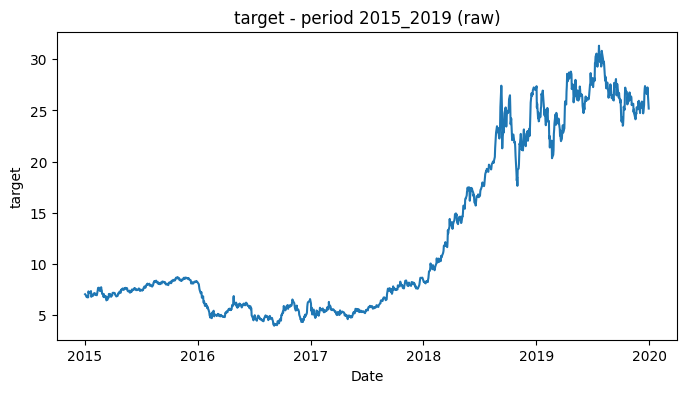

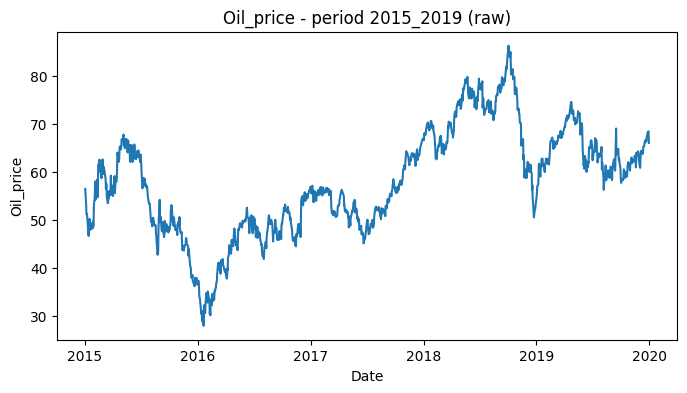

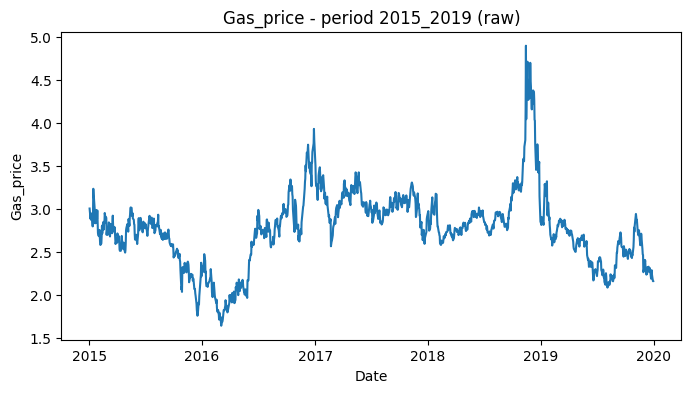

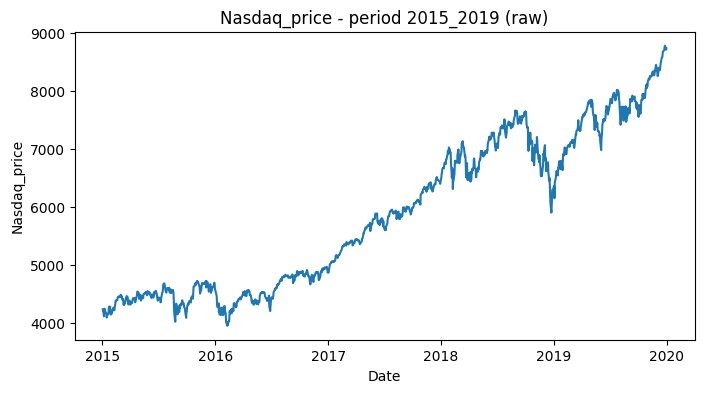

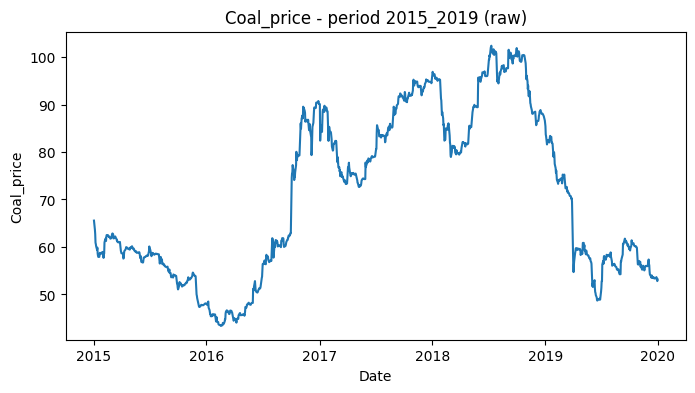

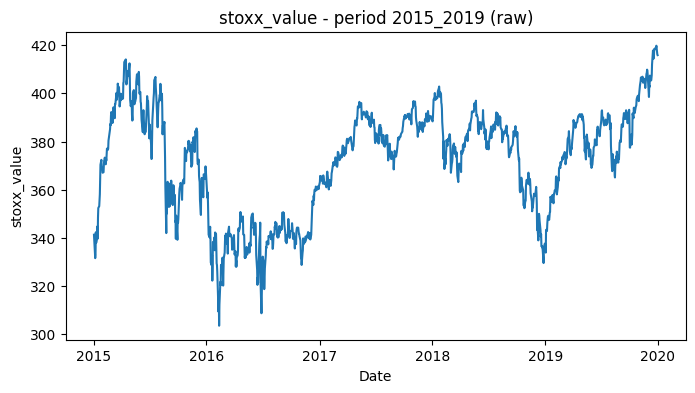

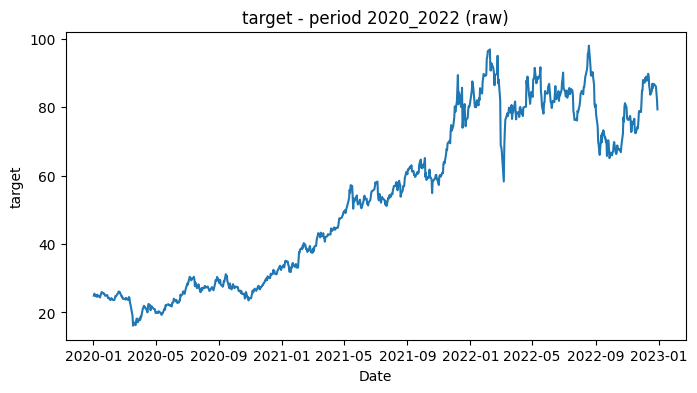

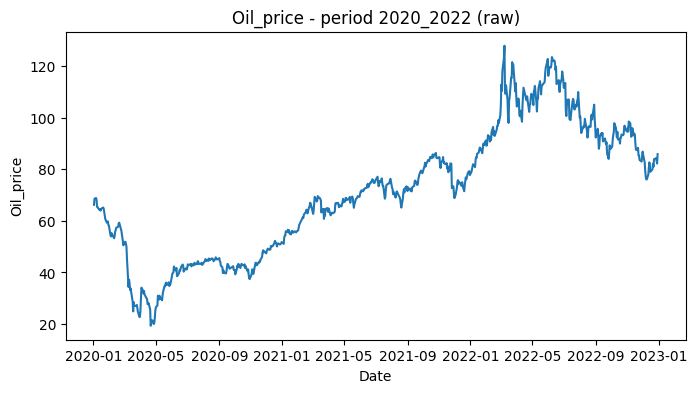

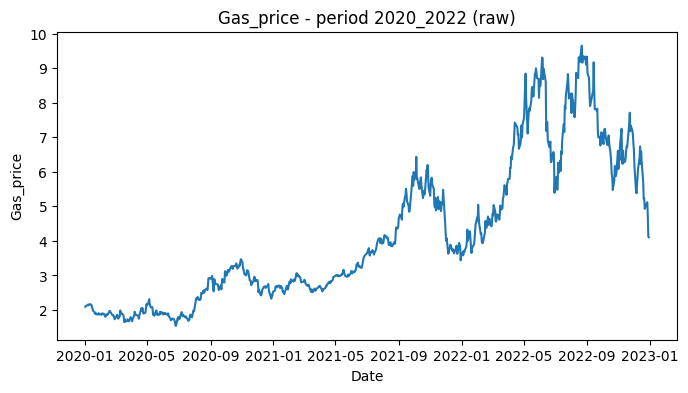

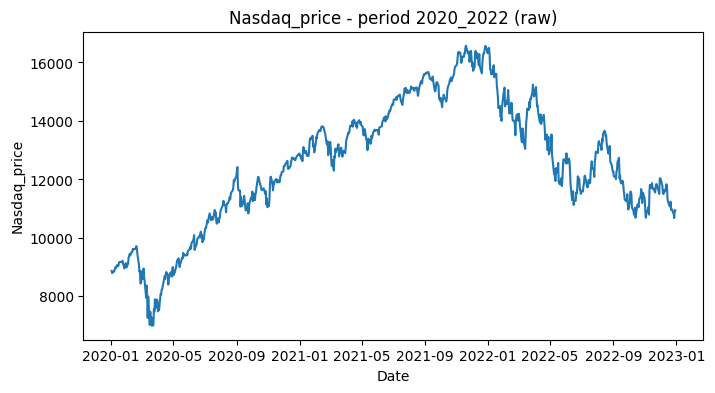

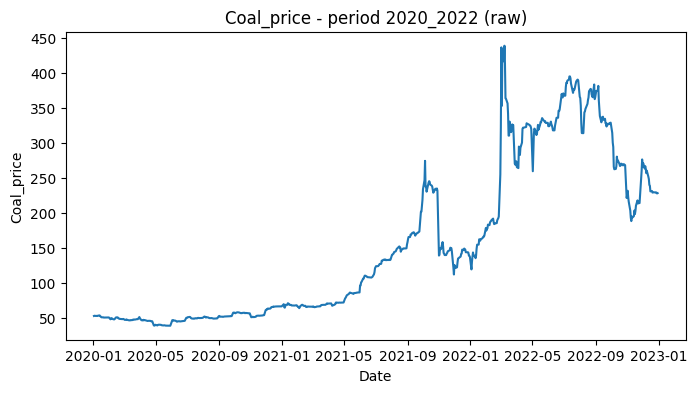

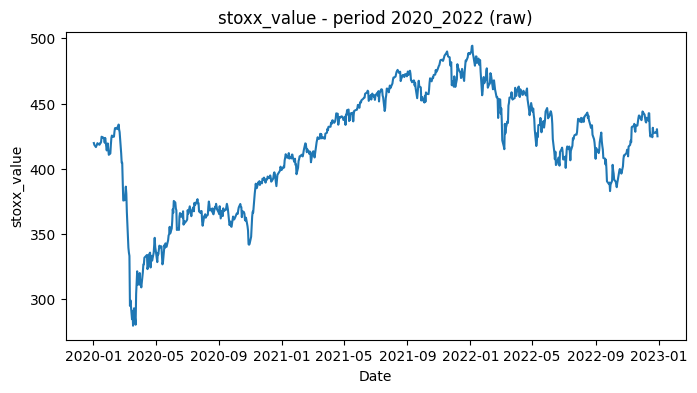

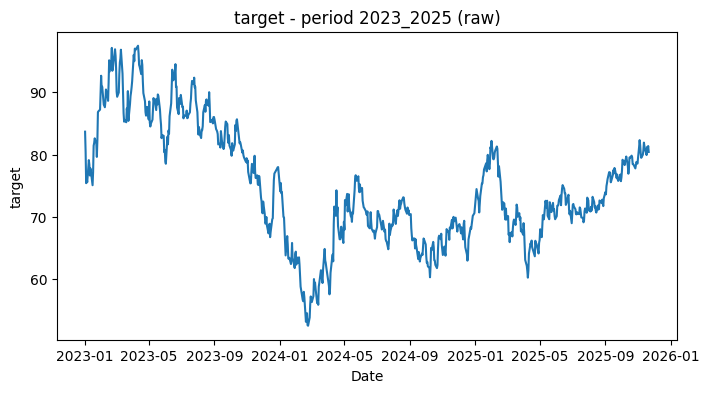

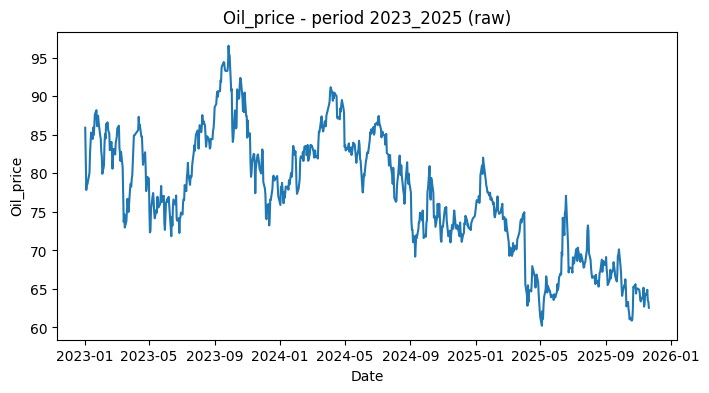

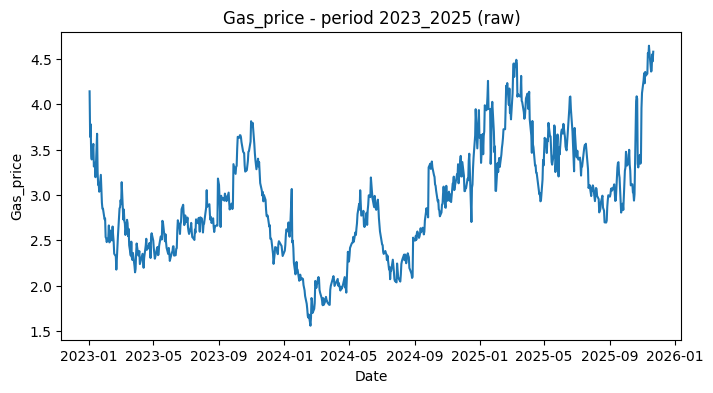

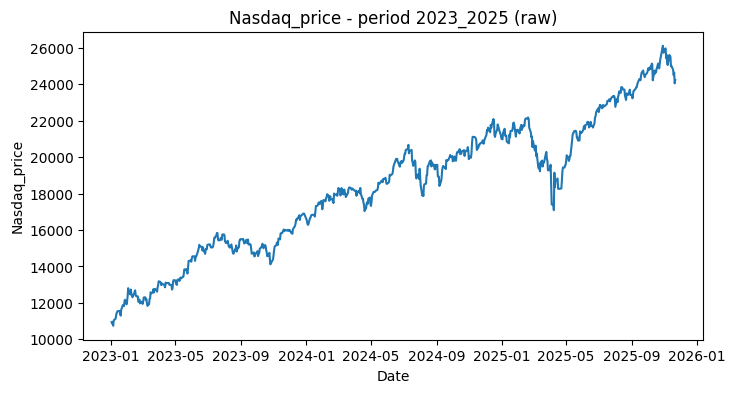

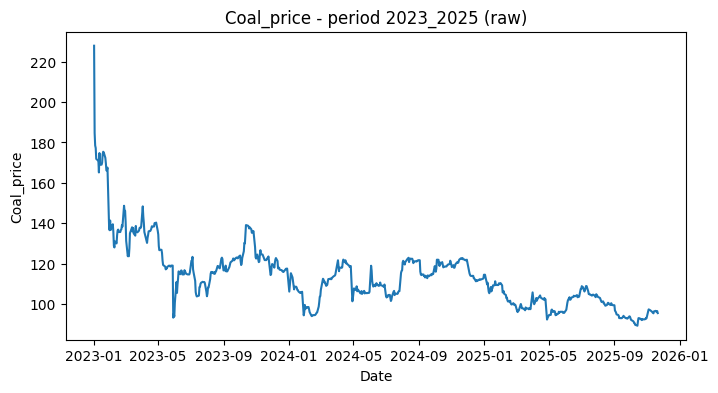

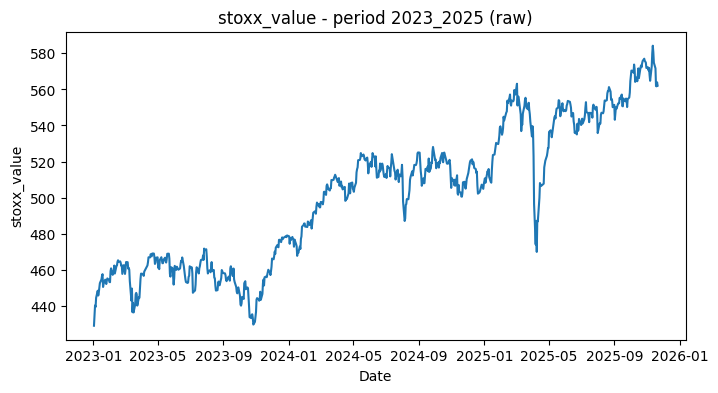

In [30]:
plot_series(data_periods, cols, kind='line', transform='raw')

### Logged time series

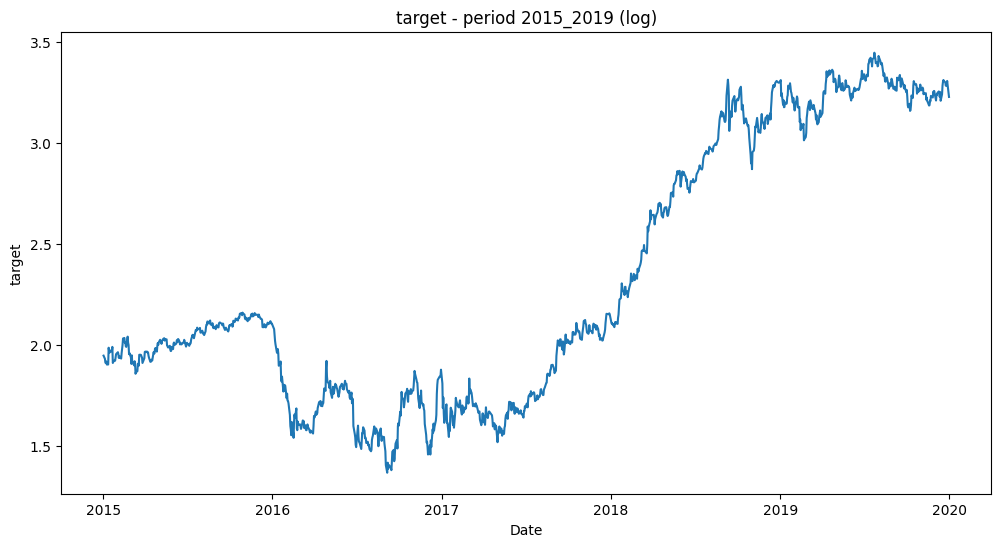

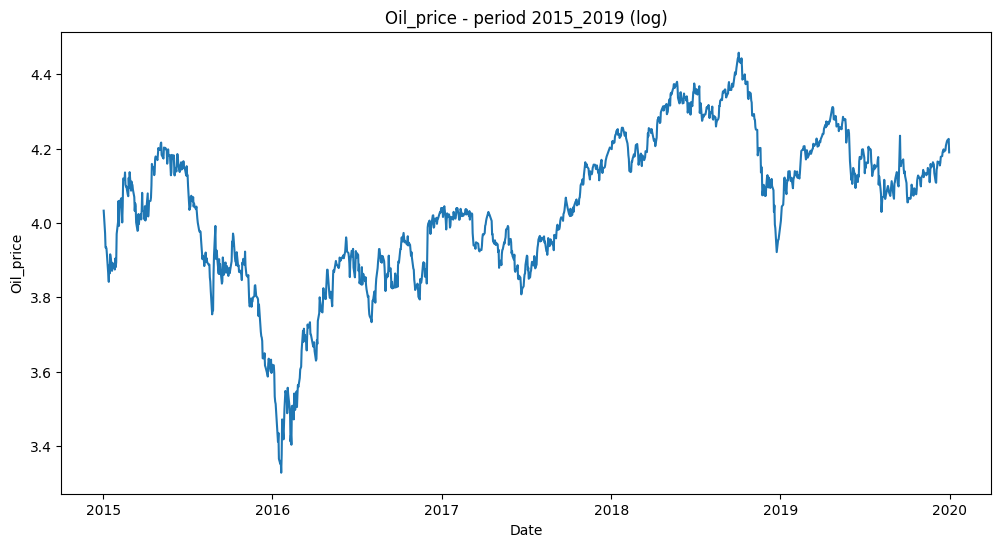

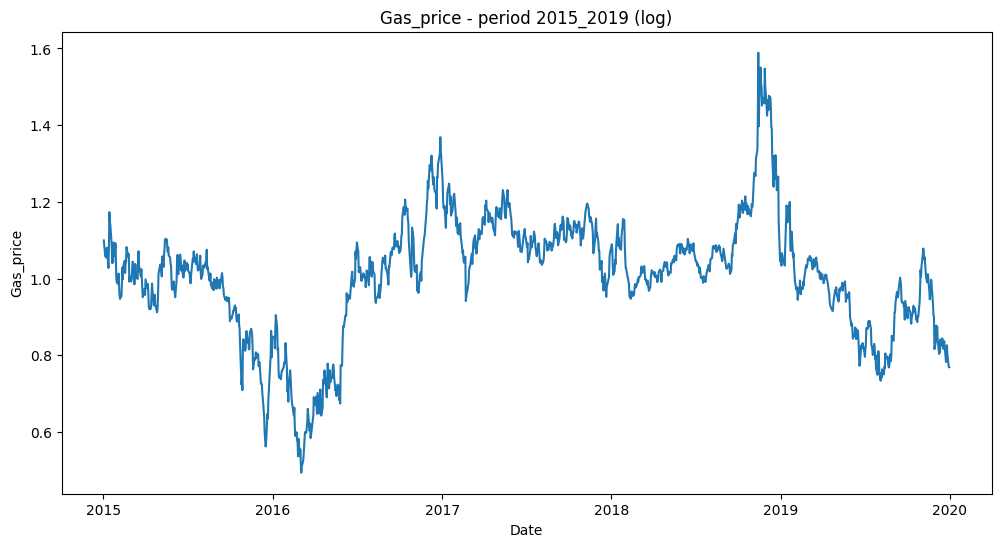

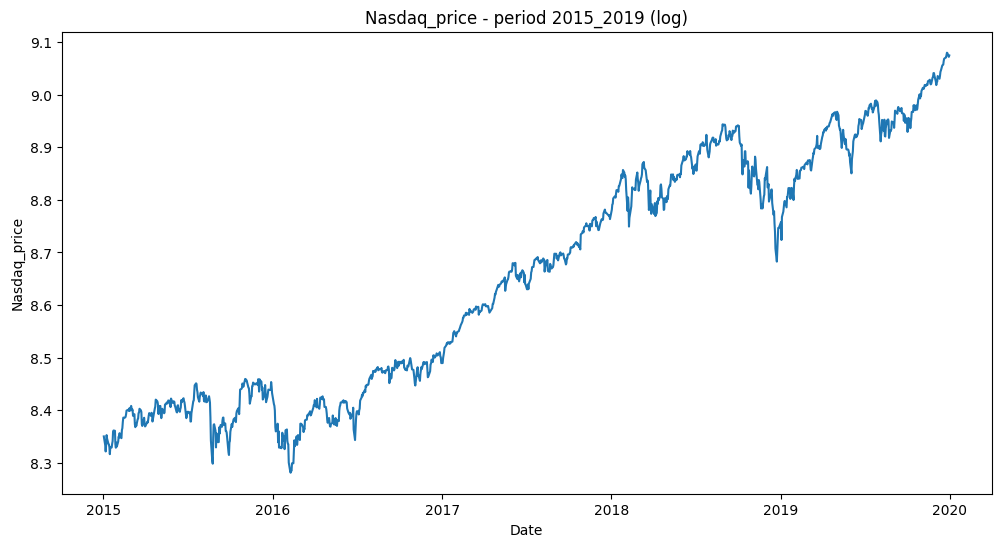

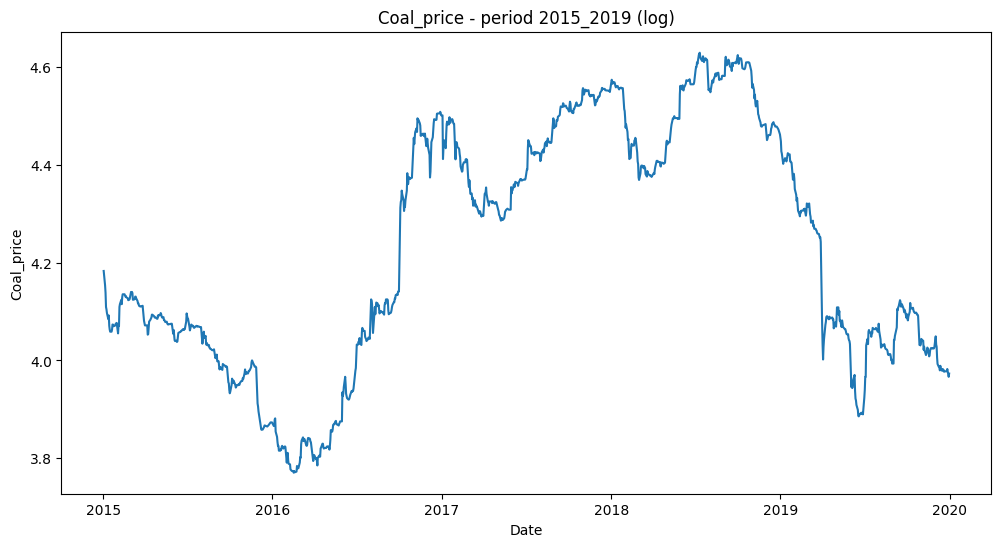

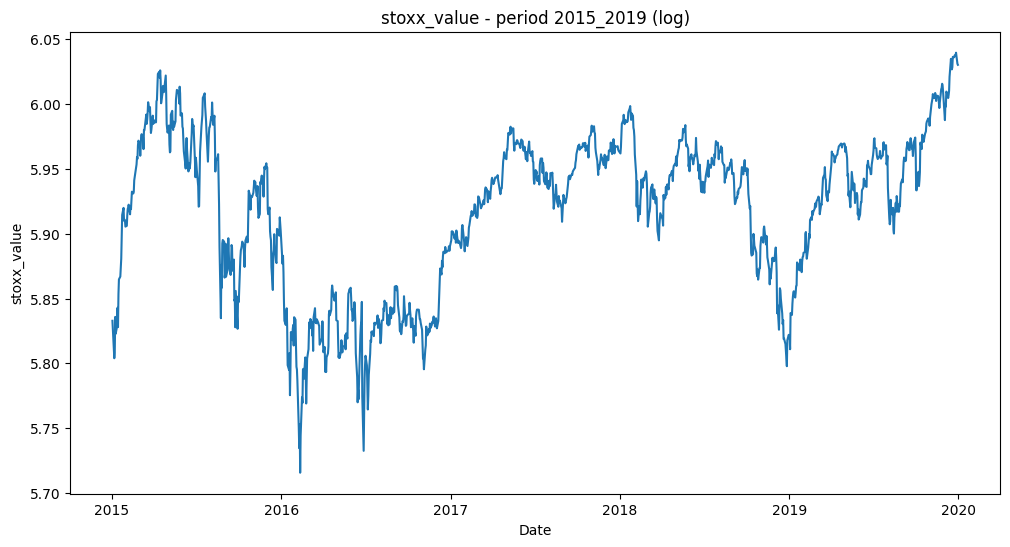

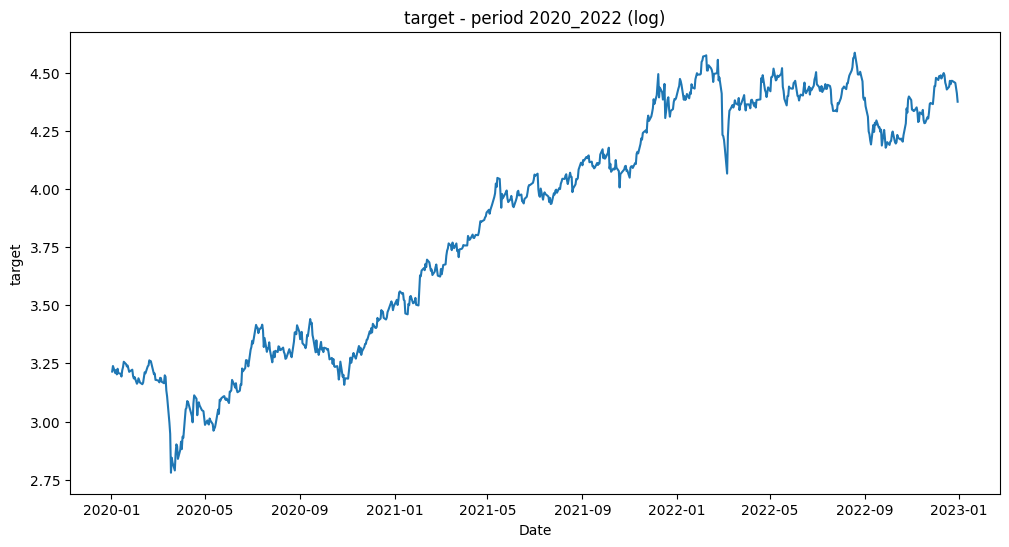

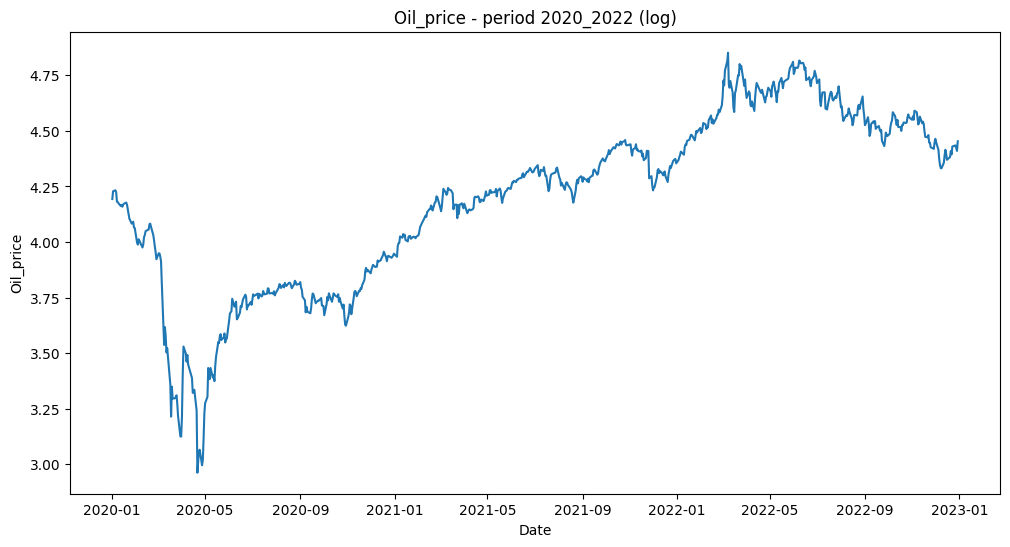

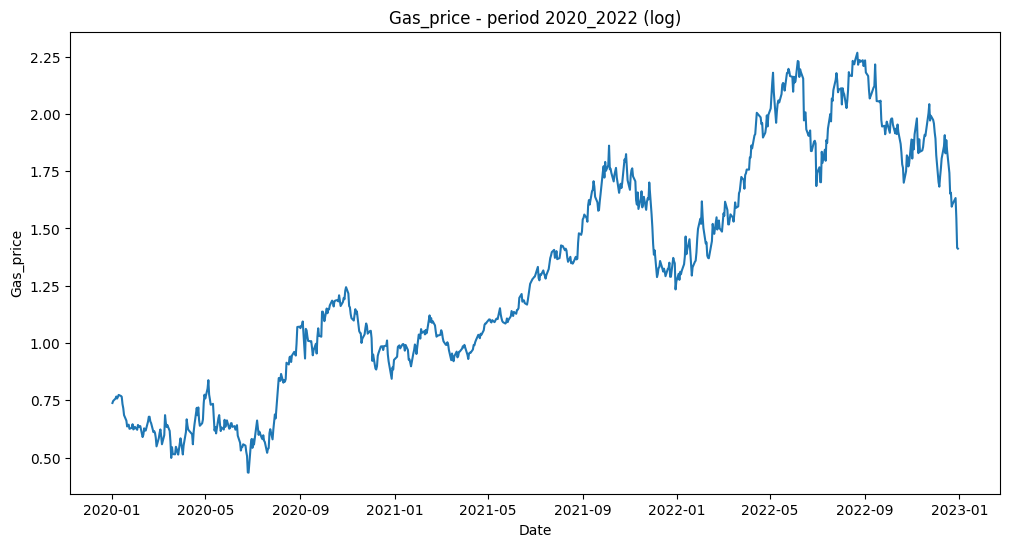

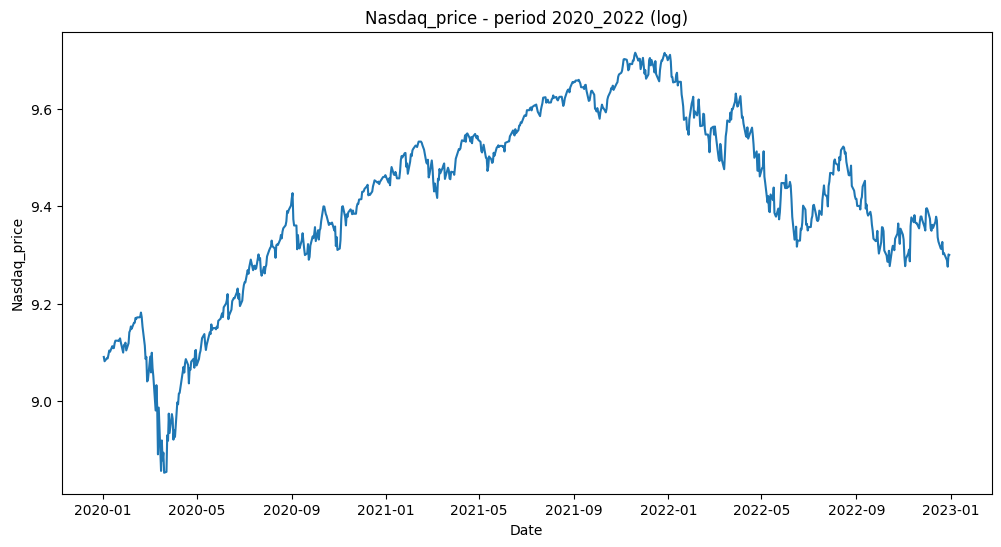

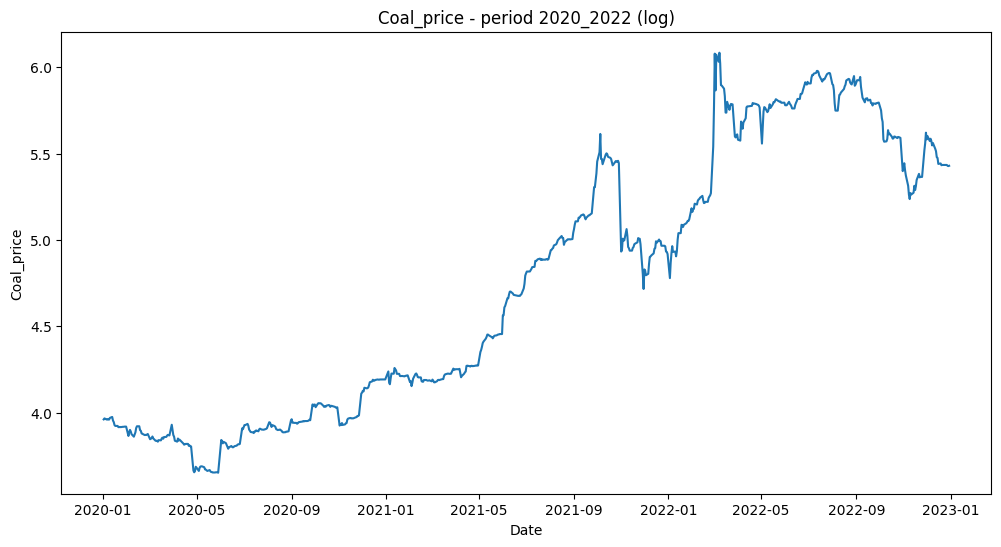

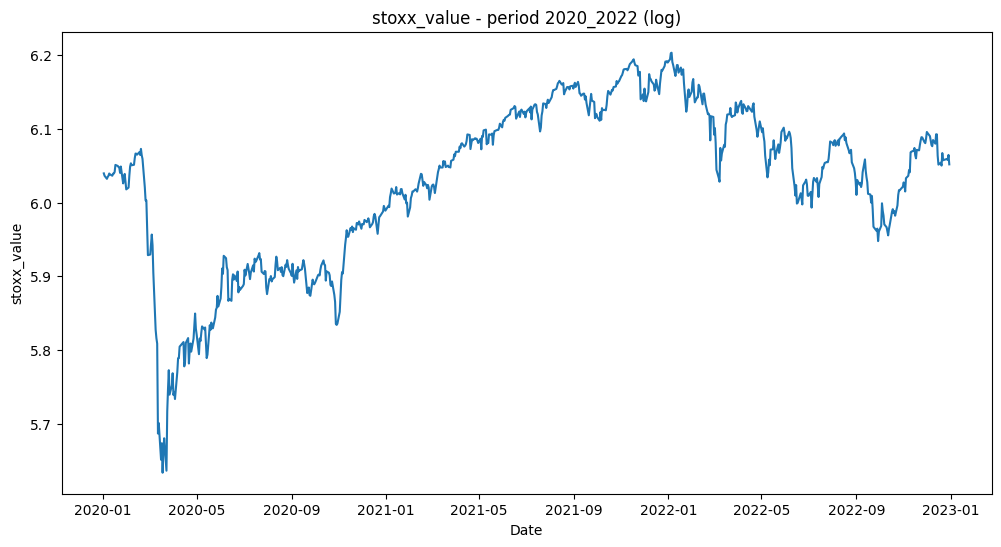

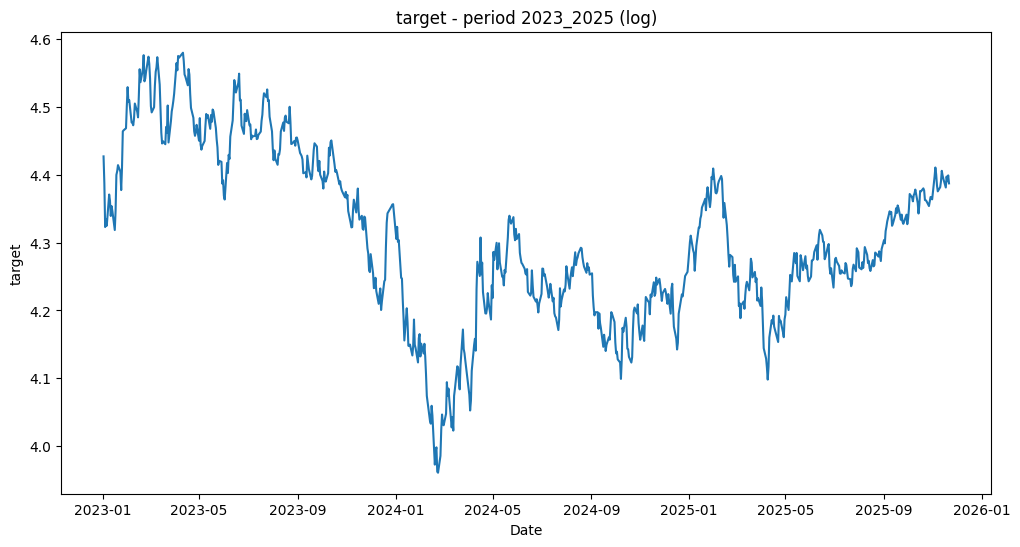

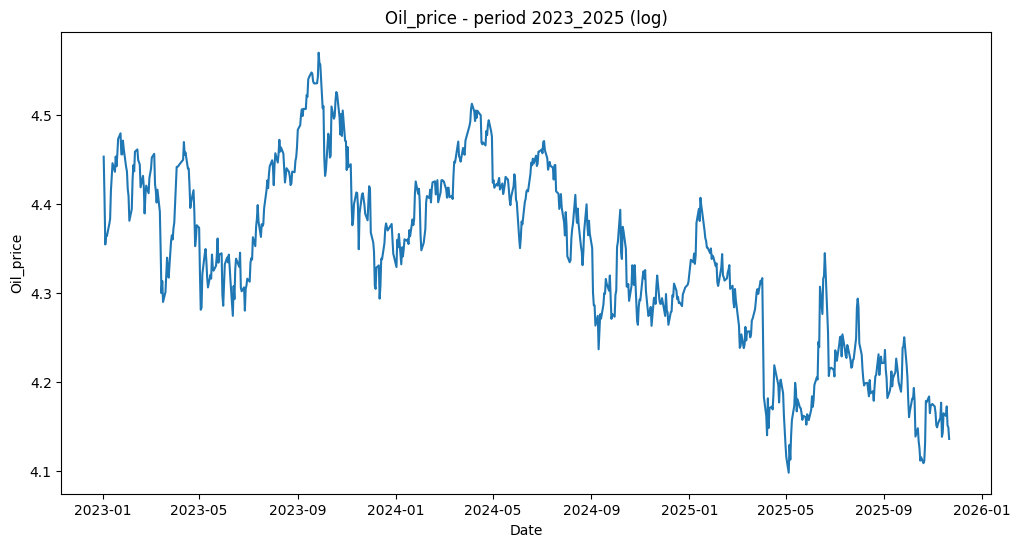

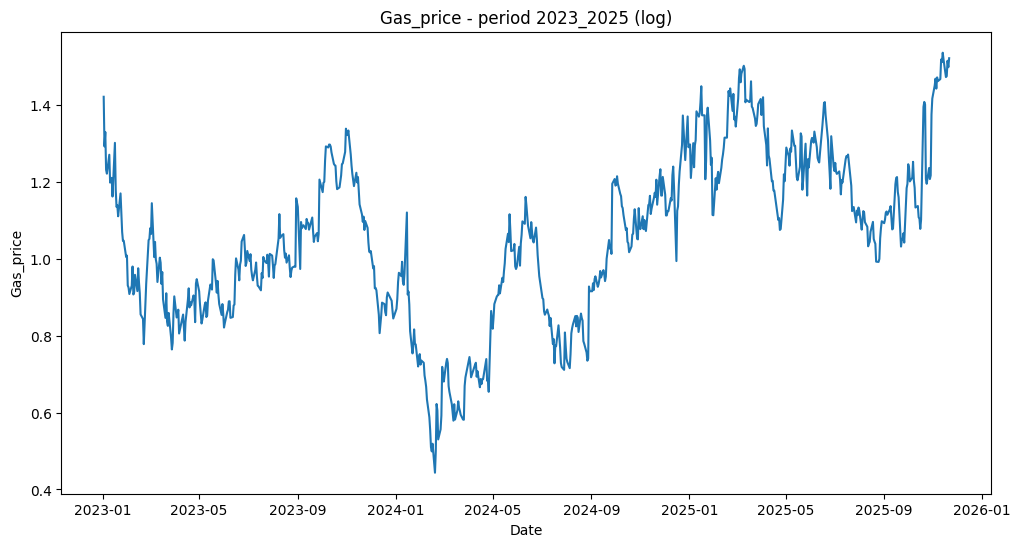

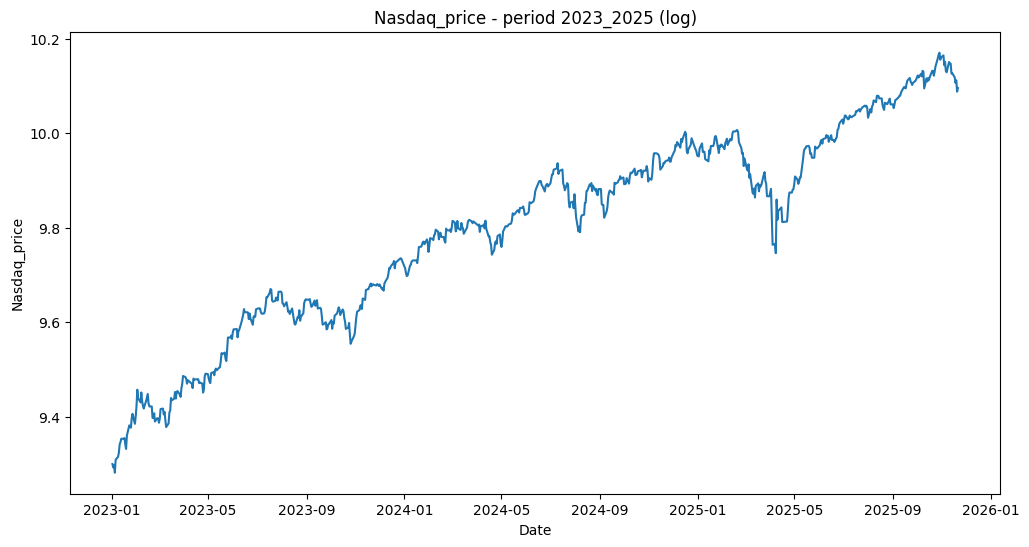

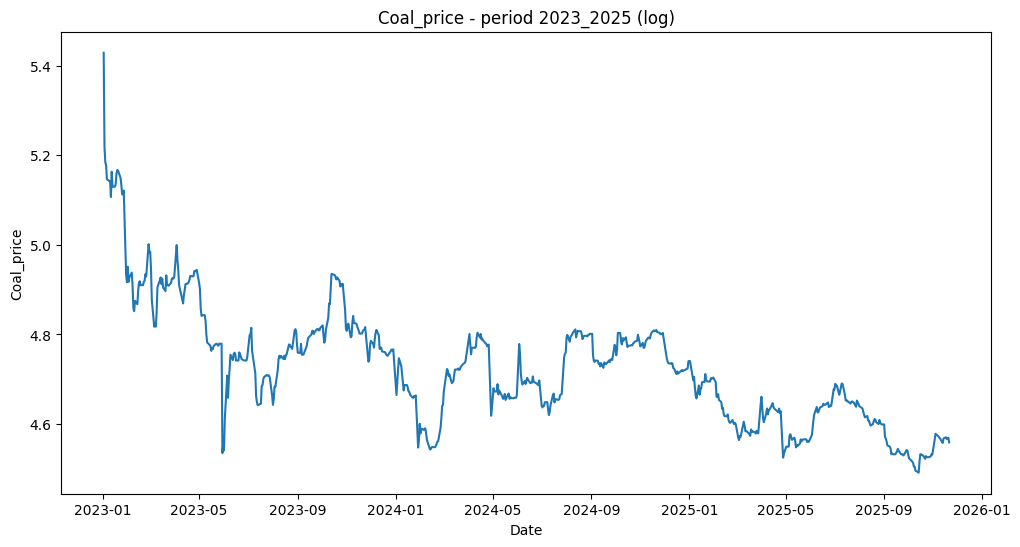

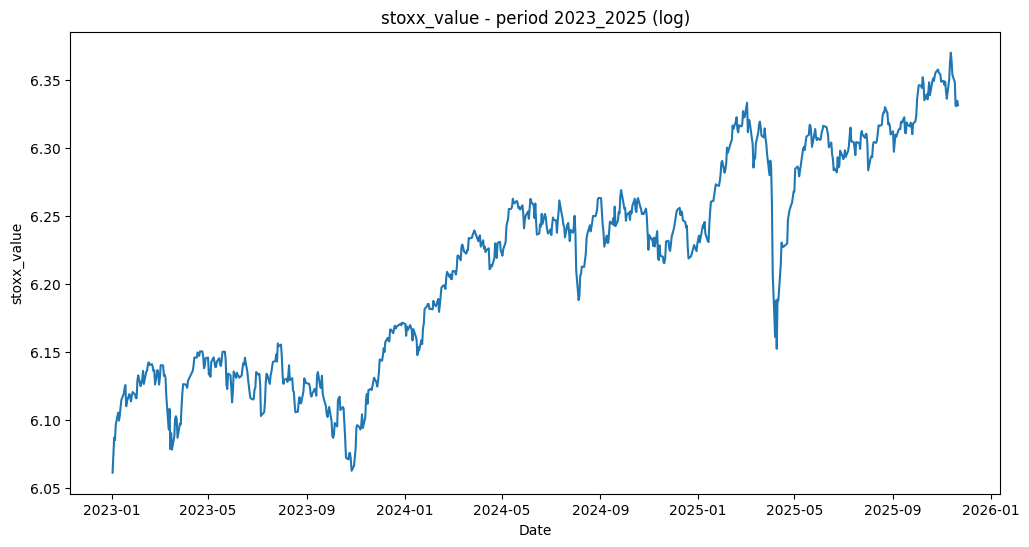

In [31]:
plot_series(data_periods, cols, kind='line', transform='log')

### CO2 price vs other variables

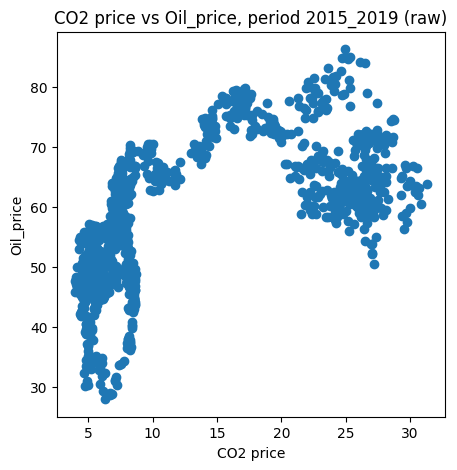

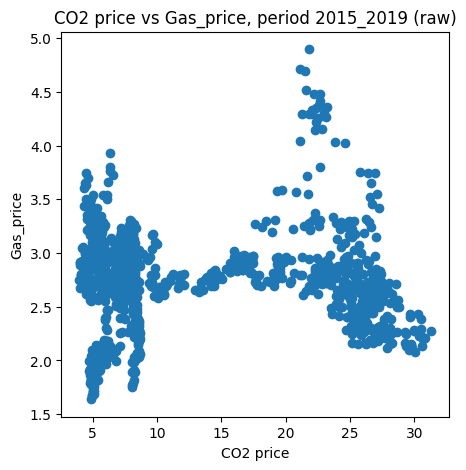

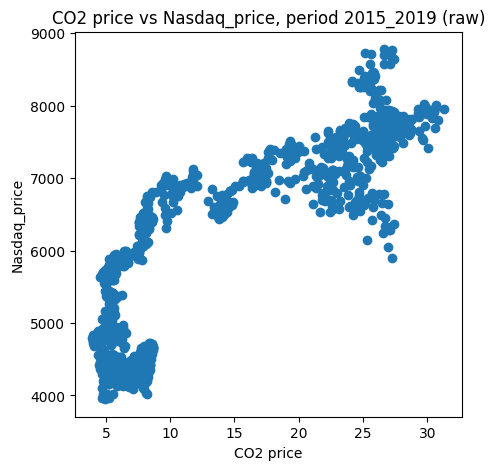

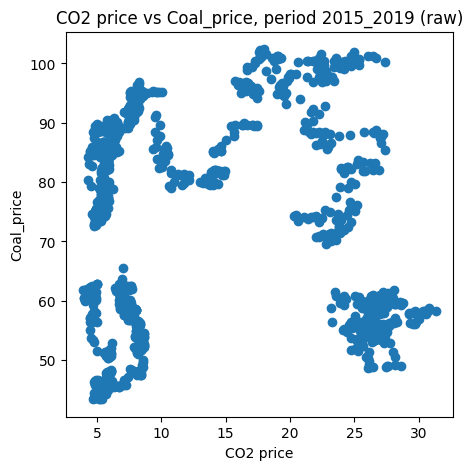

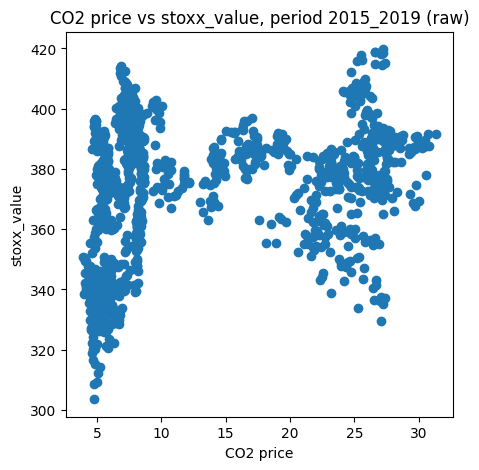

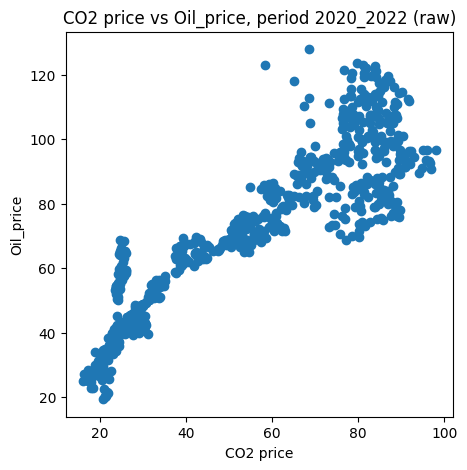

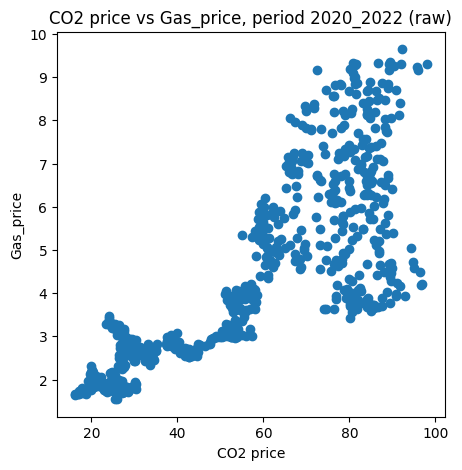

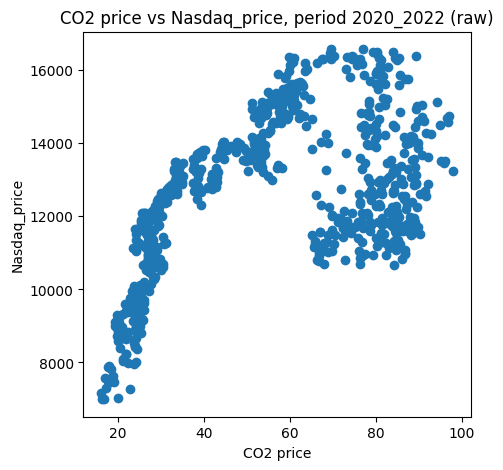

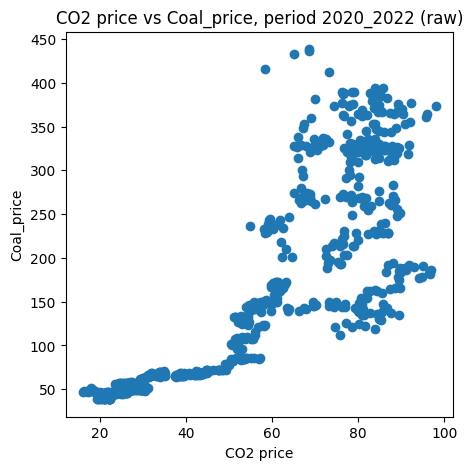

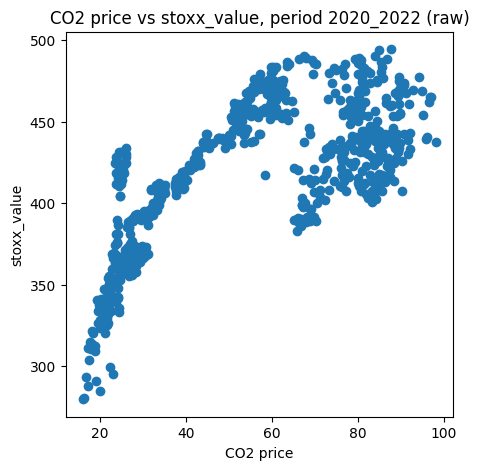

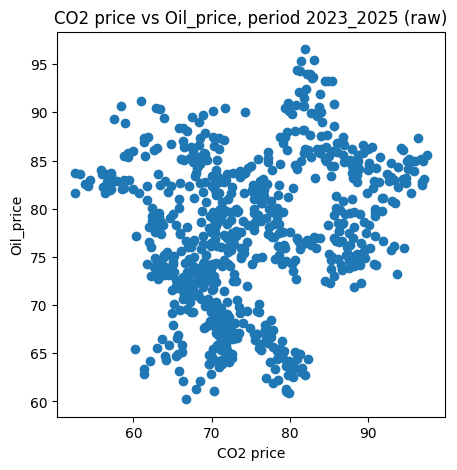

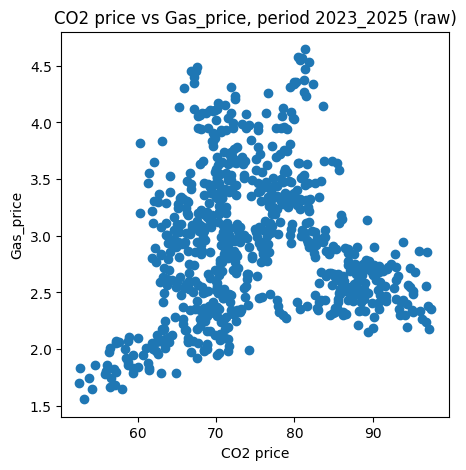

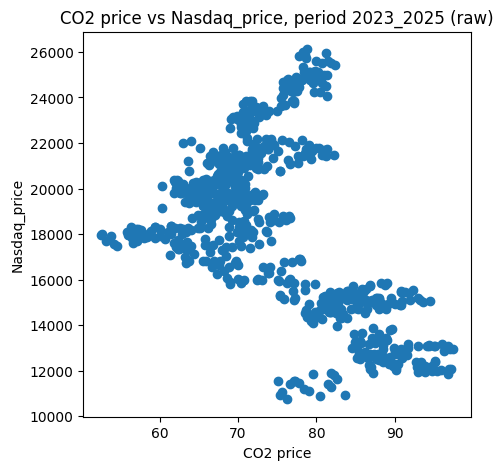

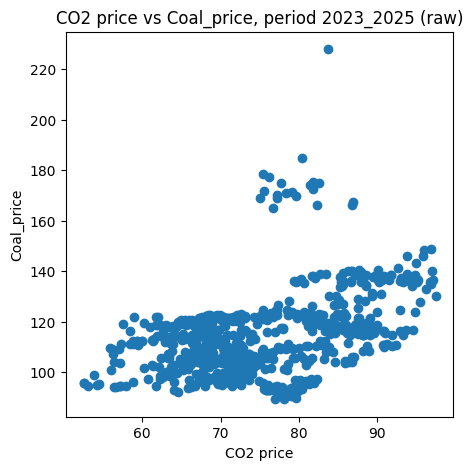

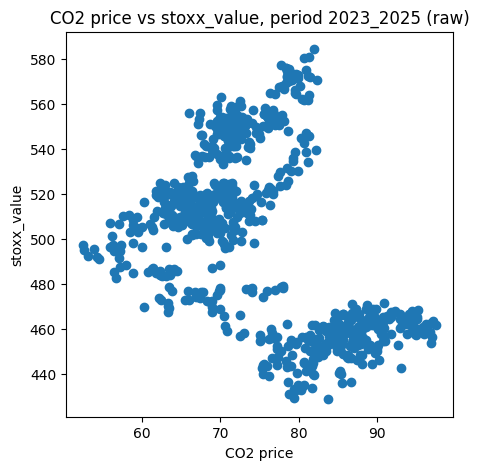

In [32]:
plot_series(data_periods, cols, kind='scatter', transform='raw')

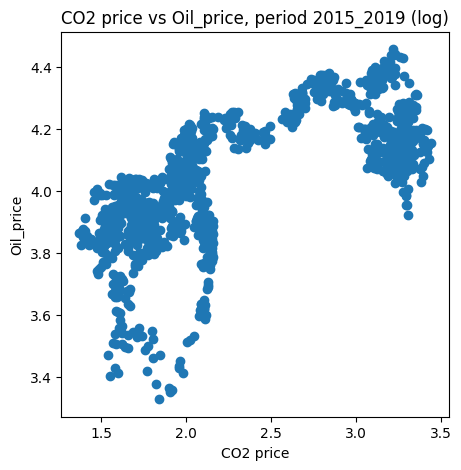

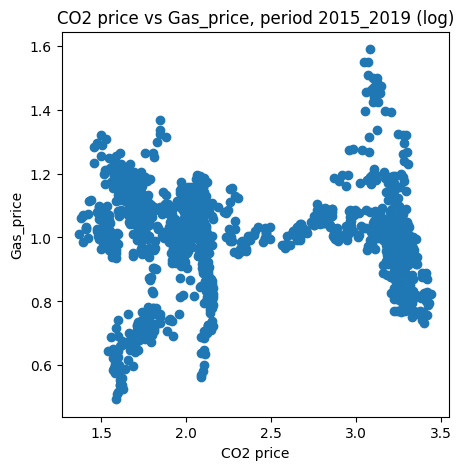

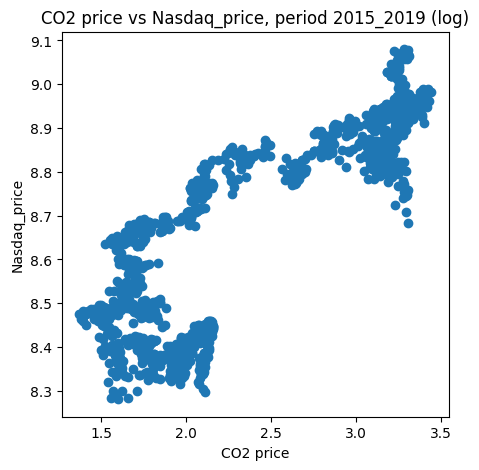

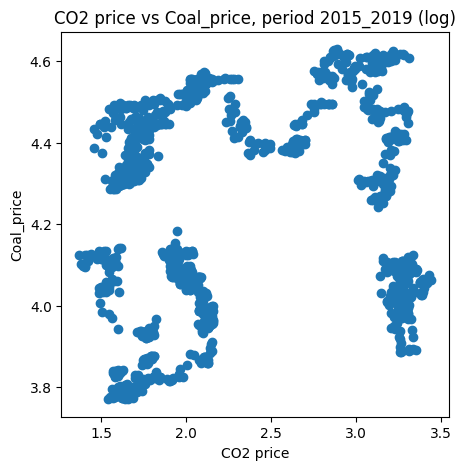

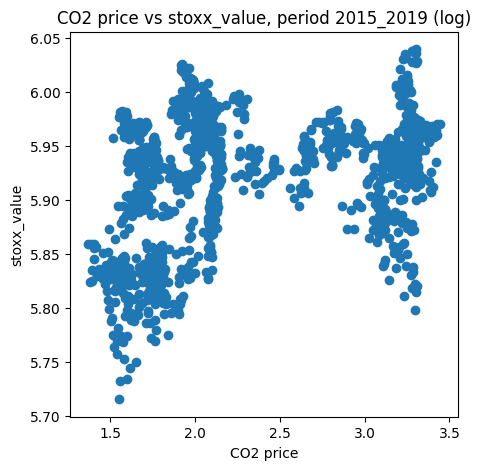

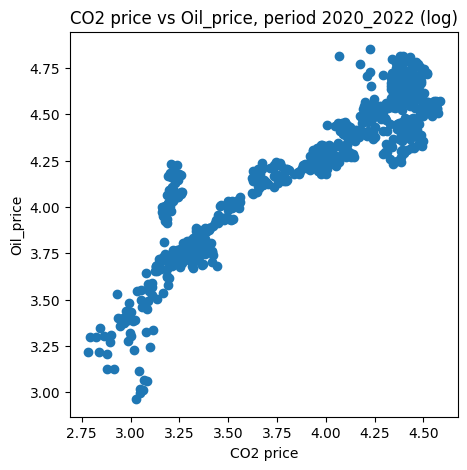

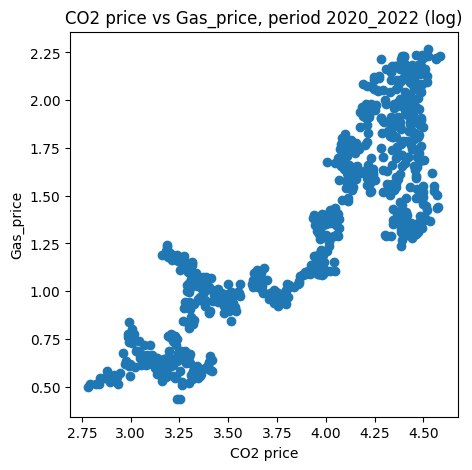

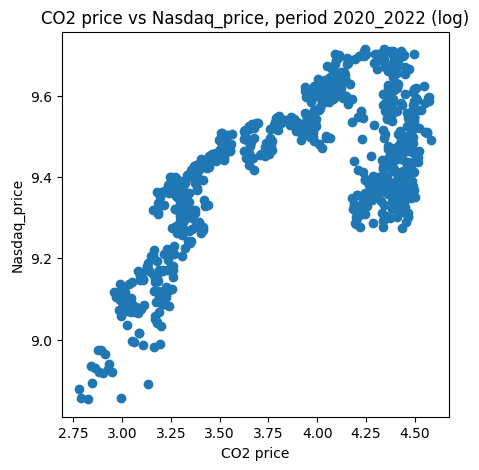

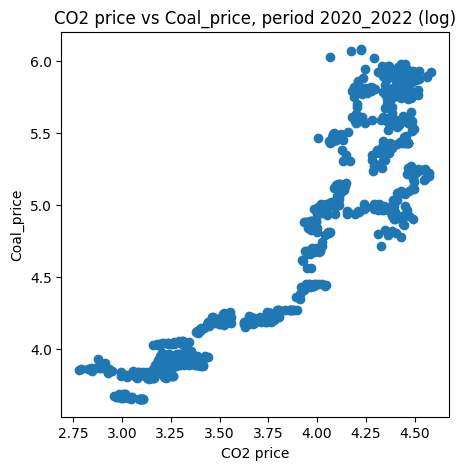

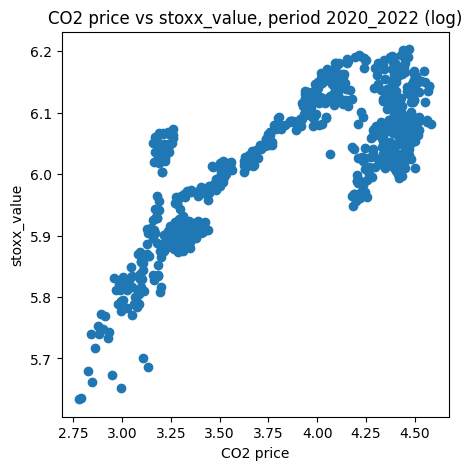

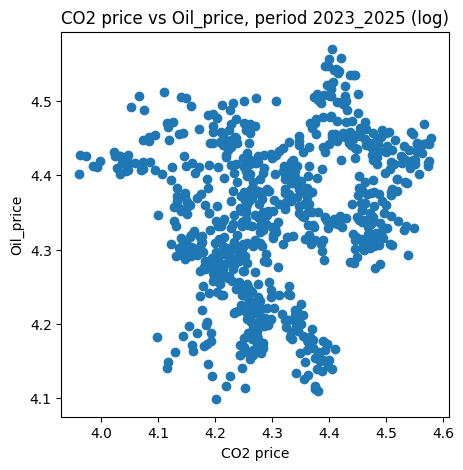

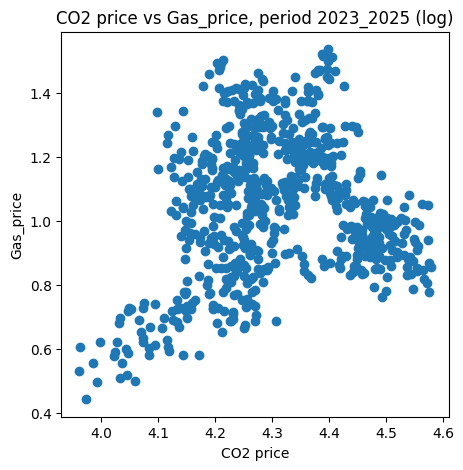

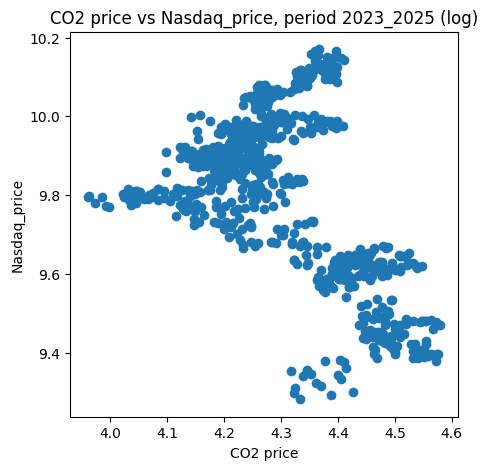

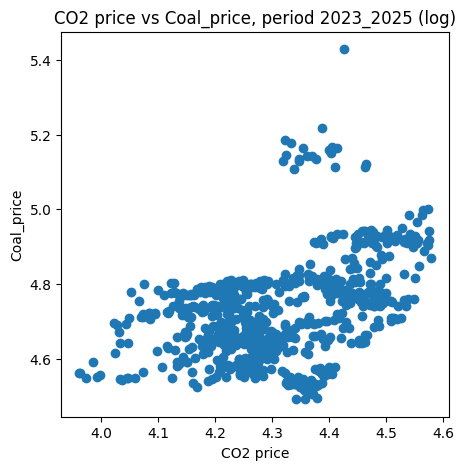

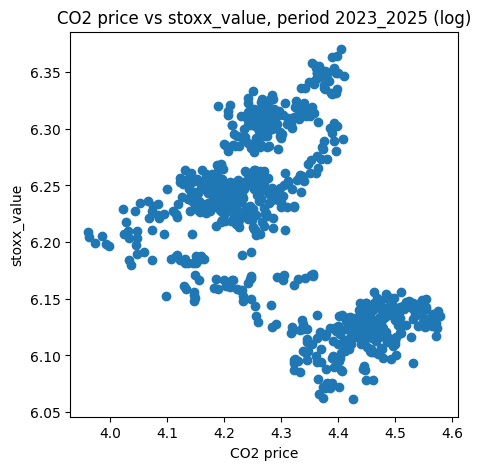

In [33]:
plot_series(data_periods, cols, kind='scatter', transform='log')

## Statistical tests (ADF + cointegration) - one call

In [40]:
results = run_analysis(
    data_periods,
    cols,
    target=TARGET,
    transforms=("raw", "log"),   # które wersje szeregów testować
    alpha_adf=0.01,
    alpha_coint=0.05,
    trends=("c", "ct", "ctt"),         # trendy w coint(); filtruj po kolumnie 'trend'
    n_regressors=(1, 2),         # 1 = target vs pojedyncza zmienna, 2 = target vs pary
)
adf, coint_res = results["adf"], results["coint"]

### ADF

In [35]:
# odpowiednik list `stationary` (poziomy) - szeregi stacjonarne już w poziomach
adf.query("series == 'level' and stationary")

,period,transform,series,variable,adf_stat,p_value,stationary
56,2023_2025,raw,level,Coal_price,-3.956066,0.001659,True


In [36]:
# odpowiednik list `not_stationary` (różnice) - szeregi NIEstacjonarne po różnicowaniu
adf.query("series == 'diff' and not stationary")

,period,transform,series,variable,adf_stat,p_value,stationary


### Cointegration

In [44]:
# tylko przypadki, gdzie wykryto kointegrację
coint_res.query("cointegrated").sort_values("n_regressors")

,period,transform,trend,n_regressors,regressors,p_value,cointegrated
90,2020_2022,raw,c,1,Oil_price,0.010866,True
135,2020_2022,log,c,1,Oil_price,0.002271,True
148,2020_2022,log,ct,1,stoxx_value,0.025318,True
185,2023_2025,raw,ctt,1,Gas_price,0.024157,True
230,2023_2025,log,ctt,1,Gas_price,0.021073,True
114,2020_2022,raw,c,2,Oil_price & stoxx_value,0.041320,True
132,2020_2022,raw,c,2,Coal_price & stoxx_value,0.014042,True
112,2020_2022,raw,ct,2,Oil_price & Coal_price,0.027557,True
152,2020_2022,log,ctt,2,Oil_price & Gas_price,0.035894,True
153,2020_2022,log,c,2,Oil_price & Nasdaq_price,0.030499,True


In [42]:
# przegląd p-value: wiersze = (transformacja, trend, zmienne), kolumny = okresy
coint_res.pivot_table(
    index=["n_regressors", "transform", "trend", "regressors"],
    columns="period",
    values="p_value",
).round(4)

period                                                   2015_2019  2020_2022  \
n_regressors transform trend regressors                                         
1            log       c     Coal_price                     0.9847     0.0686   
                             Gas_price                      0.9792     0.3980   
                             Nasdaq_price                   0.5643     0.9744   
                             Oil_price                      0.6734     0.0023   
                             stoxx_value                    0.8530     0.3322   
...                                                            ...        ...   
2            raw       ctt   Nasdaq_price & stoxx_value     0.4239     0.4857   
                             Oil_price & Coal_price         0.9829     0.3005   
                             Oil_price & Gas_price          0.9896     0.1023   
                             Oil_price & Nasdaq_price       0.7198     0.0695   
                             Oil_price & stoxx_value        0.1652     0.1220   

period                                                   2023_2025  
n_regressors transform trend regressors                             
1            log       c     Coal_price                     0.3424  
                             Gas_price                      0.3737  
                             Nasdaq_price                   0.3161  
                             Oil_price                      0.4237  
                             stoxx_value                    0.3091  
...                                                            ...  
2            raw       ctt   Nasdaq_price & stoxx_value     0.1668  
                             Oil_price & Coal_price         0.2006  
                             Oil_price & Gas_price          0.0480  
                             Oil_price & Nasdaq_price       0.1931  
                             Oil_price & stoxx_value        0.1700  

[90 rows x 3 columns]